# XGBoost con las 100 columnas más importantes

El XGBoost de `modelo_a_xgboost/2_entrenamiento.ipynb` usa 719 columnas, pero no todas pesan lo mismo: muchas casi no aparecen en los árboles. El objetivo de este notebook es ver si un **XGBoost con solo las 100 columnas más importantes** clasifica igual de bien. Si es así, conviene usarlo: es un modelo más simple y, al predecir una noche nueva, hay que calcular menos rasgos.

Todo lo demás queda igual que en `modelo_a_xgboost/2_entrenamiento.ipynb`: los hiperparámetros, el enmascaramiento de canales, las semillas y los folds. Así, la única diferencia entre los dos modelos es el número de columnas.

No tiene preprocesamiento propio: las 100 columnas salen de la misma tabla de 719 rasgos de `modelo_a_xgboost/1_preprocesamiento.ipynb`, con los mismos valores. Se corre después de `modelo_a_xgboost/2_entrenamiento.ipynb`, y el modelo de 719 columnas no se toca: el nuevo queda aparte, en `modelo/modelo_a_xgboost_100_features/`, y sus predicciones en `data/procesados/modelo_a_xgboost_100_features/folds/`, que es lo que lee el meta-modelo.

El notebook se organiza así:

1. **Librerías**
2. **Rutas y parámetros**
3. **Datos:** partición por sujeto, combinaciones de canales y tabla de rasgos.
4. **Las 100 columnas más importantes**
5. **Enmascaramiento de canales**
6. **Entrenamiento:** validación cruzada y modelo final.
7. **Resultados:** 100 frente a 719 columnas.
8. **Usar el modelo guardado**
9. **Conclusiones**

## 1. Librerías

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

Con `PRUEBA = True` se entrena 1 fold con 50 rondas, solo para comprobar que todo corre.

In [2]:
# Raíz del repositorio: la carpeta que tiene particiones.json
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())
PROCESADOS = RAIZ / "data" / "procesados" / "modelo_a_xgboost"           # rasgos y predicciones del de 719
SALIDA = RAIZ / "data" / "procesados" / "modelo_a_xgboost_100_features"           # predicciones del de 100
MODELO_719 = RAIZ / "modelo" / "modelo_a_xgboost"
MODELO = RAIZ / "modelo" / "modelo_a_xgboost_100_features"

SEED = 42
PRUEBA = False
N_COLUMNAS = 100
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]

## 3. Datos

### Partición y combinaciones de canales

Los mismos 16 sujetos de test, los mismos 5 folds sobre los 62 de desarrollo y las mismas 12 combinaciones de `modelo_a_xgboost/2_entrenamiento.ipynb`.

In [3]:
# Partición por sujeto y las 12 combinaciones
particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = {k: tuple(v) for k, v in particion["combinaciones"].items()}
print(f"{len(particion['sujetos_test'])} sujetos de test, {len(particion['sujetos_desarrollo'])} de desarrollo, "
      f"{len(particion['folds'])} folds, {len(CONFIGS)} combinaciones")

16 sujetos de test, 62 de desarrollo, 5 folds, 12 combinaciones


### Tabla de rasgos

Leemos la tabla de 719 rasgos de `modelo_a_xgboost/1_preprocesamiento.ipynb`.

In [4]:
# Lectura de la tabla de rasgos
META_COLS = ["night", "subject", "epoch_idx", "y"]
full = pd.read_parquet(PROCESADOS / "rasgos.parquet")
cols_719 = [c for c in full.columns if c not in META_COLS]
print(f"tabla: {full.shape[0]:,} épocas × {len(cols_719)} columnas")

tabla: 195,767 épocas × 719 columnas


## 4. Las 100 columnas más importantes

Para medir cuánto aporta cada columna usamos la **ganancia total** del XGBoost de 719 columnas: cuánto bajó la pérdida, sumado en todas las divisiones de todos los árboles que usan esa columna. Una columna que el modelo casi no usa tiene ganancia cercana a cero.

La ganancia sale del modelo final de `modelo_a_xgboost/2_entrenamiento.ipynb` (`modelo/modelo_a_xgboost/`), que se entrenó solo con los 62 sujetos de desarrollo: el test no interviene en la elección.

In [5]:
# Ganancia total de cada columna en el XGBoost de 719 columnas
assert json.loads((MODELO_719 / "columnas.json").read_text()) == cols_719
modelo_719 = xgb.Booster()
modelo_719.load_model(MODELO_719 / "xgb.json")
g = modelo_719.get_score(importance_type="total_gain")
ganancia = pd.Series([g.get(f"f{i}", 0.0) for i in range(len(cols_719))], index=cols_719)
orden = ganancia.sort_values(ascending=False, kind="stable")
acumulada = orden.cumsum() / orden.sum()
print(f"la mitad de la ganancia está en {(acumulada < 0.5).sum() + 1} columnas y el 80 % en {(acumulada < 0.8).sum() + 1}")

la mitad de la ganancia está en 38 columnas y el 80 % en 174


La ganancia está muy concentrada: unas pocas columnas hacen la mayor parte del trabajo.

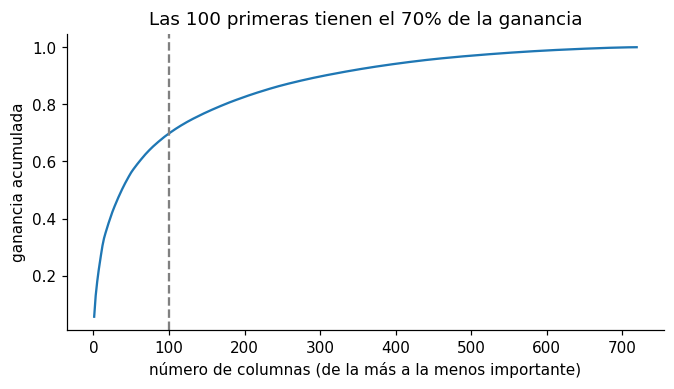

In [6]:
# Ganancia acumulada al ir sumando columnas, de la más a la menos importante
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(acumulada) + 1), acumulada.values)
ax.axvline(N_COLUMNAS, color="gray", ls="--")
ax.set_xlabel("número de columnas (de la más a la menos importante)")
ax.set_ylabel("ganancia acumulada")
ax.set_title(f"Las {N_COLUMNAS} primeras tienen el {acumulada.iloc[N_COLUMNAS - 1]:.0%} de la ganancia")
plt.show()

Elegimos las 100 primeras y las dejamos **en el orden de la tabla**, no en el de la ganancia: XGBoost sortea columnas por posición (`colsample_bytree`), así que el orden tiene que ser fijo.

In [7]:
# Las 100 columnas elegidas, en el orden de la tabla
elegidas = set(orden.index[:N_COLUMNAS])
cols = [c for c in cols_719 if c in elegidas]
orden.head(10).to_frame("ganancia").assign(**{"% del total": lambda d: (d.ganancia / orden.sum() * 100).round(1)})

,ganancia,% del total
pz_ap_slope,302043.218750,5.6
pz_ratio_delta_beta,212647.515625,4.0
time_hours_since_lights_off,184124.281250,3.4
fpz_rel_beta,134785.828125,2.5
pz_ap_r2,127846.132812,2.4
fpz_abs_beta_z_roll15,116018.453125,2.2
pz_rel_beta,102622.140625,1.9
fpz_dwt_cD3_logenergy_z_roll15,97556.359375,1.8
fpz_dwt_cD2_petrosian,94488.562500,1.8
pz_higuchi,90533.398438,1.7


Cuántas columnas quedan de cada canal. La mayoría son de EEG; del EOG y del EMG quedan pocas.

In [8]:
# Columnas por canal: 719 frente a 100
canal = lambda c: c.split("_")[0]  # noqa: E731
pd.DataFrame({"719 columnas": pd.Series([canal(c) for c in cols_719]).value_counts(),
              "100 columnas": pd.Series([canal(c) for c in cols]).value_counts()}).fillna(0).astype(int).T

,fpz,pz,eog,emg,time
719 columnas,278,278,132,30,1
100 columnas,51,40,5,3,1


## 5. Enmascaramiento de canales

Igual que en `modelo_a_xgboost/2_entrenamiento.ipynb`: a cada época se le sortea una de las 12 combinaciones y las columnas de los canales ausentes se ponen en NaN. Las funciones son las mismas; solo cambia la lista de columnas.

In [9]:
# Funciones para saber qué columnas dependen de cada canal y apagar los ausentes
CHANNELS_ALL = ("fpz", "pz", "eog", "emg")
CROSS = {"corr_fpz": "fpz"}  # rasgos con prefijo de un canal que también usan otro


def channel_index(cols):
    ch = np.array([c.split("_")[0] for c in cols])
    idx = {c: set(np.where(ch == c)[0]) for c in CHANNELS_ALL}
    for i, col in enumerate(cols):
        for key, other in CROSS.items():
            if key in col:
                idx[other].add(i)
    return {c: np.array(sorted(v), dtype=int) for c, v in idx.items()}


def apply_mask(X, configs_per_row, idx):
    """Pone en NaN las columnas de los canales ausentes de cada fila. Modifica X."""
    names = np.asarray(configs_per_row)
    for cfg, chans in CONFIGS.items():
        r = np.where(names == cfg)[0]
        if len(r) == 0:
            continue
        for ch in CHANNELS_ALL:
            if ch not in chans:
                X[np.ix_(r, idx[ch])] = np.nan
    return X


def random_mask(df, cols, idx, rng):
    X = df[cols].to_numpy(np.float32, copy=True)
    return apply_mask(X, rng.choice(list(CONFIGS), size=len(X)), idx)


idx = channel_index(cols)
pd.Series({c: len(v) for c, v in idx.items()}).to_frame("columnas").T

,fpz,pz,eog,emg
columnas,51,40,5,3


## 6. Entrenamiento

### Hiperparámetros y funciones

Los mismos hiperparámetros y pesos por clase de `modelo_a_xgboost/2_entrenamiento.ipynb`, y las mismas funciones para entrenar y predecir.

In [10]:
# Hiperparámetros del XGBoost y pesos por clase
PARAMS = {
    "objective": "multi:softprob", "tree_method": "hist", "eval_metric": "mlogloss", "n_jobs": -1,
    "learning_rate": 0.03394046833983564, "max_depth": 10, "min_child_weight": 43.70990468130503,
    "subsample": 0.9041986740582306, "colsample_bytree": 0.4436910153386966,
    "reg_lambda": 0.019634341572933336, "gamma": 3.4211651325607844,
}
ALPHA = 0.4401524937396013
N_MAX = 50 if PRUEBA else 2000


def class_weights(y, alpha=ALPHA):
    return compute_sample_weight("balanced", y) ** alpha

In [11]:
# Función para entrenar un XGBoost con canales enmascarados
def rows(subjects, labeled_only=True):
    m = full.subject.isin(list(subjects))
    return full[m & (full.y >= 0)] if labeled_only else full[m]


def fit(train_subj, rng, val_subj=None, n_estimators=N_MAX):
    tr = rows(train_subj)
    p = {**PARAMS, "random_state": SEED}
    Xtr = random_mask(tr, cols, idx, rng)
    if val_subj is None:
        model = xgb.XGBClassifier(**p, n_estimators=n_estimators)
        model.fit(Xtr, tr.y, sample_weight=class_weights(tr.y), verbose=False)
        return model
    va = rows(val_subj)
    Xva = random_mask(va, cols, idx, rng)
    model = xgb.XGBClassifier(**p, n_estimators=n_estimators, early_stopping_rounds=100)
    model.fit(Xtr, tr.y, sample_weight=class_weights(tr.y), eval_set=[(Xva, va.y)],
              sample_weight_eval_set=[class_weights(va.y)], verbose=False)
    return model

In [12]:
# Funciones para predecir con las 12 combinaciones y guardar las predicciones
def predict_all_configs(model, subjects):
    """combinación -> noche -> (y, probabilidades), con todas las épocas enmascaradas igual."""
    d = rows(subjects, labeled_only=False)
    base_x = d[cols].to_numpy(np.float32)
    groups = d.groupby("night").indices
    out = {}
    for cfg in CONFIGS:
        proba = model.predict_proba(apply_mask(base_x.copy(), [cfg] * len(base_x), idx))
        out[cfg] = {n: (d.y.values[i], proba[i]) for n, i in groups.items()}
    return out


def save_preds(path, preds):
    arr = {}
    for cfg, p in preds.items():
        for n, (y, pr) in p.items():
            arr[f"{cfg}__{n}__y"], arr[f"{cfg}__{n}__pred"] = y, pr
    np.savez_compressed(path, **arr)


def load_preds(path):
    z = np.load(path)
    out = {}
    for k in z.files:
        cfg, n, kind = k.split("__")
        if kind == "y":
            out.setdefault(cfg, {})[n] = (z[k], z[f"{cfg}__{n}__pred"])
    return out

### Validación cruzada (5 folds)

Con las mismas semillas de máscaras (`[42, fold]`). Las predicciones de cada fold se guardan en `data/procesados/modelo_a_xgboost_100_features/folds/`: si se corta, al volver a correr retoma desde el último fold guardado.

In [13]:
# Validación cruzada: un modelo por fold
FOLDS = SALIDA / ("folds_prueba" if PRUEBA else "folds")
FOLDS.mkdir(parents=True, exist_ok=True)
folds = particion["folds"][:1] if PRUEBA else particion["folds"]

rondas = []
for f in folds:
    path, meta = FOLDS / f"fold_{f['fold']}.npz", FOLDS / f"fold_{f['fold']}.json"
    if not meta.exists():
        rng = np.random.default_rng([SEED, f["fold"]])
        m = fit(f["train"], rng, val_subj=f["val"])
        save_preds(path, predict_all_configs(m, f["test"]))
        meta.write_text(json.dumps({"rondas": m.best_iteration + 1}))
    rondas.append(json.loads(meta.read_text())["rondas"])
    print(f"fold {f['fold'] + 1}: {rondas[-1]} rondas")

fold 1: 703 rondas
fold 2: 753 rondas
fold 3: 477 rondas
fold 4: 374 rondas
fold 5: 407 rondas


### Modelo final

Con los 62 sujetos de desarrollo y el promedio de rondas de los folds (semilla de máscaras `[42, 99]`). Predice el test y se guarda en `modelo/modelo_a_xgboost_100_features/`.

In [14]:
# Modelo final con los 62 sujetos de desarrollo
n_final = int(np.mean(rondas))
final_path = FOLDS / "final.npz"
if not final_path.exists():
    final = fit(particion["sujetos_desarrollo"], np.random.default_rng([SEED, 99]), n_estimators=n_final)
    save_preds(final_path, predict_all_configs(final, particion["sujetos_test"]))
    if not PRUEBA:
        MODELO.mkdir(parents=True, exist_ok=True)
        final.save_model(MODELO / "xgb.json")
        (MODELO / "columnas.json").write_text(json.dumps(cols))
        print("guardado:", MODELO.relative_to(RAIZ))
print(f"modelo final: {n_final} rondas")

guardado: modelo/modelo_a_xgboost_100_features
modelo final: 542 rondas


Juntamos las predicciones fuera de fold y las de test, de los dos modelos: el de 100 columnas y el de 719 de `modelo_a_xgboost/2_entrenamiento.ipynb`.

In [15]:
# Predicciones fuera de fold (CV) y de test, con 100 y con 719 columnas
def cv_y_test(carpeta):
    oof = {c: {} for c in CONFIGS}
    for f in folds:
        for c, p in load_preds(carpeta / f"fold_{f['fold']}.npz").items():
            oof[c].update(p)
    return oof, load_preds(carpeta / "final.npz")


oof, test = cv_y_test(FOLDS)
oof_719, test_719 = cv_y_test(PROCESADOS / "folds")
rondas_719 = [json.loads((PROCESADOS / "folds" / f"fold_{f['fold']}.json").read_text())["rondas"] for f in folds]
pd.DataFrame({"719 columnas": rondas_719, "100 columnas": rondas},
             index=[f"fold {f['fold'] + 1}" for f in folds]).T

,fold 1,fold 2,fold 3,fold 4,fold 5
719 columnas,592,656,660,508,644
100 columnas,703,753,477,374,407


## 7. Resultados

### Métricas

Las mismas de `modelo_a_xgboost/2_entrenamiento.ipynb`: **MF1** (la principal), **κ de Cohen** y **F1 de N1**. Solo se evalúan las épocas con etiqueta.

In [16]:
# Funciones para calcular las métricas
def compute_metrics(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(5), average=None, zero_division=0)
    return {"acc": accuracy_score(y_true, y_pred), "mf1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"f1_{s}": v for s, v in zip(ESTADIOS, f1)},
            "confusion": confusion_matrix(y_true, y_pred, labels=range(5))}


def metrics_of(preds):
    y = np.concatenate([y for y, _ in preds.values()])
    p = np.concatenate([p.argmax(1) for _, p in preds.values()])
    return compute_metrics(y[y >= 0], p[y >= 0])

### 100 frente a 719 columnas

MF1 de cada combinación en la CV (62 sujetos de desarrollo) y en el test (16 sujetos), y la diferencia. La última fila es el promedio de las 12 combinaciones.

In [17]:
# MF1 de CV y de test por combinación, con 719 y con 100 columnas
filas = []
for c in CONFIGS:
    cv7, cv1 = metrics_of(oof_719[c])["mf1"], metrics_of(oof[c])["mf1"]
    te7, te1 = metrics_of(test_719[c])["mf1"], metrics_of(test[c])["mf1"]
    filas.append({"combinación": c, "CV 719": cv7, "CV 100": cv1, "Δ CV": cv1 - cv7,
                  "test 719": te7, "test 100": te1, "Δ test": te1 - te7})
tabla = pd.DataFrame(filas).set_index("combinación")
tabla.loc["promedio"] = tabla.mean()
tabla.style.format(precision=3)

,CV 719,CV 100,Δ CV,test 719,test 100,Δ test
combinación,,,,,,
fpz,0.769,0.760,-0.009,0.727,0.718,-0.009
pz,0.728,0.716,-0.012,0.701,0.690,-0.011
eeg2,0.784,0.776,-0.008,0.745,0.736,-0.009
fpz_eog,0.788,0.770,-0.018,0.755,0.735,-0.020
pz_eog,0.765,0.742,-0.023,0.724,0.705,-0.020
eeg2_eog,0.799,0.783,-0.015,0.761,0.745,-0.016
fpz_emg,0.776,0.769,-0.007,0.737,0.731,-0.006
pz_emg,0.736,0.728,-0.008,0.714,0.706,-0.007
eeg2_emg,0.789,0.781,-0.008,0.753,0.746,-0.007


La diferencia de la CV por combinación, para ver si alguna pierde más que las demás.

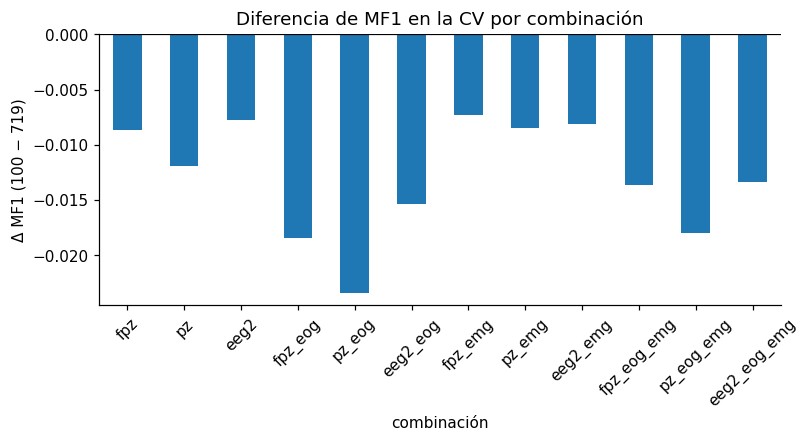

In [18]:
# Diferencia de MF1 en la CV: 100 − 719 columnas
ax = tabla["Δ CV"].drop("promedio").plot.bar(figsize=(8, 3.2), rot=45, color="tab:blue")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Δ MF1 (100 − 719)")
ax.set_title("Diferencia de MF1 en la CV por combinación")
plt.show()

### F1 por estadio

En el test, solo con Fpz-Cz y con los 4 canales: dónde pierde o gana el modelo de 100 columnas.

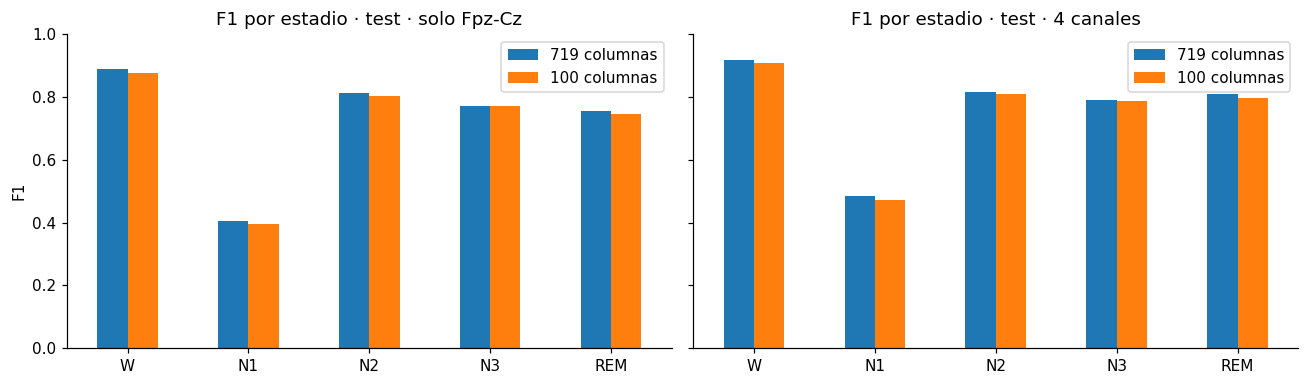

In [19]:
# F1 por estadio en el test: 719 frente a 100 columnas
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (c, nombre) in zip(axes, [("fpz", "solo Fpz-Cz"), ("eeg2_eog_emg", "4 canales")]):
    f1 = pd.DataFrame({"719 columnas": [metrics_of(test_719[c])[f"f1_{s}"] for s in ESTADIOS],
                       "100 columnas": [metrics_of(test[c])[f"f1_{s}"] for s in ESTADIOS]}, index=ESTADIOS)
    f1.plot.bar(ax=ax, rot=0)
    ax.set_title(f"F1 por estadio · test · {nombre}")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("F1")
plt.tight_layout()
plt.show()

## 8. Usar el modelo guardado

Igual que con el de 719: se carga `modelo_a_xgboost_100_features/xgb.json`, se le pasan los rasgos en el orden de su `columnas.json` (100) con los canales ausentes en NaN, y se comprueba que da lo mismo que el modelo recién entrenado.

In [20]:
# Cargar el modelo guardado y predecir una noche de test con Fpz-Cz
modelo = xgb.Booster()
modelo.load_model(MODELO / "xgb.json")
columnas = json.loads((MODELO / "columnas.json").read_text())

noche = sorted(test["fpz"])[0]
d = full[full.night == noche]
X = apply_mask(d[columnas].to_numpy(np.float32), ["fpz"] * len(d), channel_index(columnas))
proba = modelo.predict(xgb.DMatrix(X))
assert np.allclose(proba, test["fpz"][noche][1], atol=1e-6)

y, pred = d.y.values, proba.argmax(1)
m = compute_metrics(y[y >= 0], pred[y >= 0])
print(f"{noche}, solo Fpz-Cz: {len(columnas)} columnas · {len(d)} épocas · MF1 {m['mf1']:.3f} · κ {m['kappa']:.3f}")

SC4001, solo Fpz-Cz: 100 columnas · 841 épocas · MF1 0.782 · κ 0.834


## 9. Conclusiones

- La ganancia del XGBoost de 719 está muy concentrada: la mitad está en 38 columnas, y las 100 primeras tienen el 70 %.
- Con 100 columnas, el XGBoost pierde un poco en las 12 combinaciones: −0.013 de MF1 en la CV y −0.012 en el test, en promedio. Lo que más pierde son las combinaciones con EOG (−0.013 a −0.023 en la CV), porque de sus 132 columnas quedan 5.
- La pérdida se reparte entre los estadios (hasta −0.015 de F1); N3 casi no cambia.
- Solo, el modelo A de 100 columnas es algo peor. Lo que importa es si el sistema completo pierde, y eso se ve en `meta_modelo/1_entrenamiento.ipynb`.